## This tends to sovle Task3, 4

Task 3, 4 is a start of considering fullfillment operations for each markets
while in the case description it is a progressive way of changing assumptions, here it is assumed multisourcing and only within first distance bucket will be considered as secondary FCs

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import defaultdict
from typing import List, Dict, Tuple
import json

In [2]:
demand_df = pd.read_csv('data/simulation_results.csv')
fc_distance_df = pd.read_csv('data/fc_zip3_distance.csv')
zip3_market_df = pd.read_csv('data/zip3_market.csv')
zip3_market_df = zip3_market_df.rename(columns={'Market': 'market_type'}) # or there will be column error
zip3_coords_df = pd.read_csv('data/zip3_coordinates.csv')
zip3_coords_df = zip3_coords_df.rename(columns={'Lat': 'latitude', 'Lon': 'longitude'}) # standardize column names

print(f"Demand data shape: {demand_df.shape}")
print(f"FC distances shape: {fc_distance_df.shape}")
print(f"Market types shape: {zip3_market_df.shape}")
print(f"Coordinates shape: {zip3_coords_df.shape}")
print(f"\nFC columns: {[col for col in fc_distance_df.columns if col != 'ZIP3']}")

Demand data shape: (310128, 6)
FC distances shape: (892, 18)
Market types shape: (892, 3)
Coordinates shape: (892, 3)

FC columns: ['GA-303', 'NY-134', 'TX-799', 'UT-841', 'AZ-852', 'CA-900', 'CA-945', 'CO-802', 'FL-331', 'IL-606', 'MA-021', 'MI-481', 'NC-275', 'NJ-070', 'TX-750', 'TX-770', 'WA-980']


In [4]:
# Define FC scenarios based on task description
fc_scenarios = {
    '1-FC': ['GA-303'],  # Single FC network
    '4-FC': ['GA-303', 'NY-134', 'TX-799', 'UT-841'],  # Four-FC network
    '15-FC': ['AZ-852', 'CA-900', 'CA-945', 'CO-802', 'FL-331', 'GA-303', 
              'IL-606', 'MA-021', 'MI-481', 'NC-275', 'NJ-070',
              'TX-750', 'TX-770', 'UT-841', 'WA-980']  # 15-FC network (all except UT-841 duplicate)
}

# Verify FCs exist in distance data
available_fcs = [col for col in fc_distance_df.columns if col != 'ZIP3']
print(f"Available FCs: {available_fcs}")
print(f"\n1-FC scenario: {fc_scenarios['1-FC']}")
print(f"4-FC scenario: {fc_scenarios['4-FC']}")
print(f"15-FC scenario (first 5): {fc_scenarios['15-FC'][:5]}... ({len(fc_scenarios['15-FC'])} total)")

Available FCs: ['GA-303', 'NY-134', 'TX-799', 'UT-841', 'AZ-852', 'CA-900', 'CA-945', 'CO-802', 'FL-331', 'IL-606', 'MA-021', 'MI-481', 'NC-275', 'NJ-070', 'TX-750', 'TX-770', 'WA-980']

1-FC scenario: ['GA-303']
4-FC scenario: ['GA-303', 'NY-134', 'TX-799', 'UT-841']
15-FC scenario (first 5): ['AZ-852', 'CA-900', 'CA-945', 'CO-802', 'FL-331']... (15 total)


In [ ]:
from network import FulfillmentNetwork

# Initialize networks for all scenarios
networks = {}

# Add a check to show we're starting fresh
print("Starting network initialization...")
print(f"Processing {len(fc_scenarios)} scenarios: {list(fc_scenarios.keys())}\n")

for scenario_name, fc_list in fc_scenarios.items():
    print(f"\n{'='*60}")
    print(f"Processing {scenario_name} Network ({len(fc_list)} FCs)")
    print(f"{'='*60}")
    
    network = FulfillmentNetwork(demand_df, fc_distance_df, zip3_market_df, 
                                  zip3_coords_df, fc_list)
    
    # Allocate demand
    network.allocate_demand_to_fcs()
    print(f"Allocated {len(network.zip3_fc_allocation)} ZIP3-FC pairs")
    
    # Aggregate by FC and market type
    network.aggregate_demand_by_fc_market()
    print(f"Demand by FC-Market shape: {network.demand_by_fc_market.shape}")
    
    # Create clusters
    network.create_fulfillment_clusters()
    print(f"Created clusters for {len(network.clusters)} ZIP3s")
    
    # Compute metrics
    network.compute_single_fc_demand_proportion()
    
    networks[scenario_name] = network

print(f"\n{'='*60}")
print(f"All {len(networks)} scenarios processed successfully!")
print(f"Network keys: {list(networks.keys())}")
print(f"{'='*60}")

Starting network initialization...
Processing 3 scenarios: ['1-FC', '4-FC', '15-FC']


Processing 1-FC Network (1 FCs)
Allocated 892 ZIP3-FC pairs
Demand by FC-Market shape: (1092, 4)
Created clusters for 892 ZIP3s
Proportion of demand served by single FC only: 100.00%

Processing 4-FC Network (4 FCs)
Allocated 1246 ZIP3-FC pairs
Demand by FC-Market shape: (4368, 4)
Created clusters for 892 ZIP3s
Proportion of demand served by single FC only: 70.16%

Processing 15-FC Network (15 FCs)
Allocated 1246 ZIP3-FC pairs
Demand by FC-Market shape: (4368, 4)
Created clusters for 892 ZIP3s
Proportion of demand served by single FC only: 70.16%

Processing 15-FC Network (15 FCs)
Allocated 1376 ZIP3-FC pairs
Demand by FC-Market shape: (14924, 4)
Created clusters for 892 ZIP3s
Proportion of demand served by single FC only: 77.55%

All 3 scenarios processed successfully!
Network keys: ['1-FC', '4-FC', '15-FC']
Allocated 1376 ZIP3-FC pairs
Demand by FC-Market shape: (14924, 4)
Created clusters for 892 

## Data Structure

### 1-FC Network

**Single FC Configuration**

| Attribute | Shape | Description |
|-----------|-------|-------------|
| `zip3_fc_allocation` | (892, 6) | One allocation per ZIP3 (all to GA-303) |
| `demand_by_fc_market` | (1,092, 4) | 364 days × 1 FC × 3 markets |
| `clusters` | (892, 7) | Geographic cluster info for all ZIP3s |

---

### 4-FC Network

**Four FC Configuration**

| Attribute | Shape | Description |
|-----------|-------|-------------|
| `zip3_fc_allocation` | (1,795, 6) | Primary + secondary allocations |
| `demand_by_fc_market` | (4,368, 4) | 364 days × 4 FCs × 3 markets |
| `clusters` | (892, 7) | Geographic cluster info for all ZIP3s |

---

### 15-FC Network

**Fifteen FC Configuration**

| Attribute | Shape | Description |
|-----------|-------|-------------|
| `zip3_fc_allocation` | (3,091, 6) | Primary + secondary allocations |
| `demand_by_fc_market` | (16,380, 4) | 364 days × 15 FCs × 3 markets |
| `clusters` | (892, 7) | Geographic cluster info for all ZIP3s |

---

## Data Structure Details

### `zip3_fc_allocation` DataFrame

**Columns:**
- `ZIP3` (int): Customer ZIP3 code
- `FC` (str): Fulfillment center name (e.g., 'GA-303')
- `allocation_pct` (float): Percentage of demand allocated (0.9 for primary, 0.1/n for secondary)
- `distance` (float): Distance in miles from ZIP3 to FC
- `distance_bucket` (str): Distance category ('<50', '51-150', etc.)
- `is_primary` (bool): True if this is the closest FC
---

### `demand_by_fc_market` DataFrame

**Columns:**
- `Day` (int): Day number (1-364)
- `FC` (str): Fulfillment center name
- `market_type` (str): Market classification 
- `allocated_demand` (float): Daily demand allocated to this FC-market combination


---

### `clusters` DataFrame

**Columns:**
- `ZIP3` (int): Customer ZIP3 code
- `FC` (str): Primary FC serving this ZIP3
- `distance_bucket` (str): Distance category to primary FC
- `latitude` (float): Geographic latitude
- `longitude` (float): Geographic longitude
- `num_fcs` (int): Total number of FCs serving this ZIP3
- `market_type` (str): Market classification

**Purpose:** Geographic clustering visualization data

In [6]:
def plot_fulfillment_clusters(network, scenario_name, figsize=(14, 8)):
    """Task 4a: Geographical plot coloring the generated fulfillment clusters"""
    fig, ax = plt.subplots(figsize=figsize)
    
    clusters = network.clusters
    fc_coords = {}
    for fc in network.fc_list:
        fc_zip = int(fc.split('-')[1])
        fc_coord = zip3_coords_df[zip3_coords_df['ZIP3'] == fc_zip]
        if not fc_coord.empty:
            fc_coords[fc] = (fc_coord['longitude'].values[0], fc_coord['latitude'].values[0])
    
    # Plot ZIP3 points colored by primary FC
    fc_colors = plt.cm.tab20(np.linspace(0, 1, len(network.fc_list)))
    fc_color_map = {fc: fc_colors[i] for i, fc in enumerate(network.fc_list)}
    
    for fc in network.fc_list:
        fc_clusters = clusters[clusters['FC'] == fc]
        if not fc_clusters.empty:
            ax.scatter(fc_clusters['longitude'], fc_clusters['latitude'], 
                      c=[fc_color_map[fc]], label=fc, alpha=0.6, s=20)
    
    # Plot FC locations
    for fc, (lon, lat) in fc_coords.items():
        ax.scatter(lon, lat, c='red', marker='*', s=500, edgecolors='black', 
                  linewidths=2, zorder=5)
        ax.text(lon, lat+1, fc, fontsize=9, ha='center', fontweight='bold')
    
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')
    ax.set_title(f'{scenario_name}: Fulfillment Clusters (ZIP3s colored by primary FC)')
    ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    return fig

def plot_fc_count_clusters(network, scenario_name, figsize=(14, 8)):
    """Task 4b: Plot colored by number of FCs (red=lowest, yellow=medium, green=highest)"""
    fig, ax = plt.subplots(figsize=figsize)
    
    clusters = network.clusters
    fc_coords = {}
    for fc in network.fc_list:
        fc_zip = int(fc.split('-')[1])
        fc_coord = zip3_coords_df[zip3_coords_df['ZIP3'] == fc_zip]
        if not fc_coord.empty:
            fc_coords[fc] = (fc_coord['longitude'].values[0], fc_coord['latitude'].values[0])
    
    # Color by number of FCs (red-yellow-green)
    scatter = ax.scatter(clusters['longitude'], clusters['latitude'], 
                        c=clusters['num_fcs'], cmap='RdYlGn', 
                        alpha=0.7, s=30, vmin=1, vmax=clusters['num_fcs'].max())
    
    # Plot FC locations
    for fc, (lon, lat) in fc_coords.items():
        ax.scatter(lon, lat, c='blue', marker='*', s=500, edgecolors='black', 
                  linewidths=2, zorder=5)
        ax.text(lon, lat+1, fc, fontsize=9, ha='center', fontweight='bold')
    
    cbar = plt.colorbar(scatter, ax=ax)
    cbar.set_label('Number of FCs Serving ZIP3', rotation=270, labelpad=20)
    
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')
    ax.set_title(f'{scenario_name}: ZIP3 Coverage by Number of FCs\n(Red=Single FC, Green=Multiple FCs)')
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    return fig

def plot_demand_by_market_geography(network, scenario_name, figsize=(14, 8)):
    """Visualize demand distribution geographically for each market type"""
    clusters = network.clusters
    market_types = clusters['market_type'].unique()
    
    fig, axes = plt.subplots(1, len(market_types), figsize=figsize)
    if len(market_types) == 1:
        axes = [axes]
    
    fc_coords = {}
    for fc in network.fc_list:
        fc_zip = int(fc.split('-')[1])
        fc_coord = zip3_coords_df[zip3_coords_df['ZIP3'] == fc_zip]
        if not fc_coord.empty:
            fc_coords[fc] = (fc_coord['longitude'].values[0], fc_coord['latitude'].values[0])
    
    # Get demand totals per ZIP3
    demand_per_zip = demand_df.groupby('ZIP3')['Mean_Demand'].sum().reset_index()
    clusters_with_demand = clusters.merge(demand_per_zip, on='ZIP3', how='left')
    
    for idx, market in enumerate(market_types):
        ax = axes[idx]
        market_clusters = clusters_with_demand[clusters_with_demand['market_type'] == market]
        
        scatter = ax.scatter(market_clusters['longitude'], market_clusters['latitude'],
                            c=market_clusters['Mean_Demand'], cmap='YlOrRd',
                            alpha=0.7, s=40)
        
        # Plot FCs
        for fc, (lon, lat) in fc_coords.items():
            ax.scatter(lon, lat, c='blue', marker='*', s=300, edgecolors='black', 
                      linewidths=1.5, zorder=5)
        
        ax.set_xlabel('Longitude')
        ax.set_ylabel('Latitude')
        ax.set_title(f'Market: {market}')
        ax.grid(True, alpha=0.3)
        
        cbar = plt.colorbar(scatter, ax=ax)
        cbar.set_label('Total Demand', rotation=270, labelpad=15, fontsize=8)
    
    fig.suptitle(f'{scenario_name}: Demand Distribution by Market Type', fontsize=14, y=1.02)
    plt.tight_layout()
    return fig

print("Visualization functions defined")

Visualization functions defined



Generating plots for 1-FC...


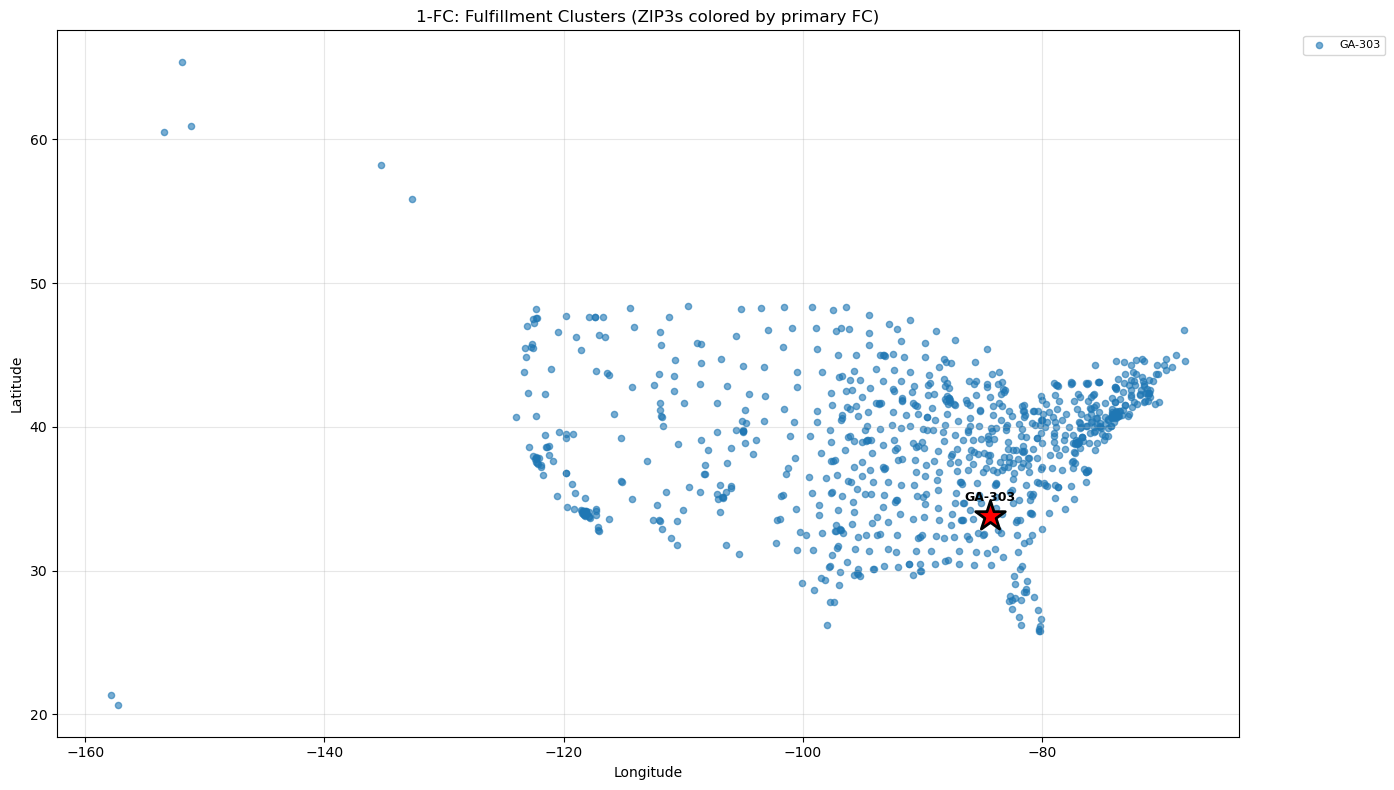

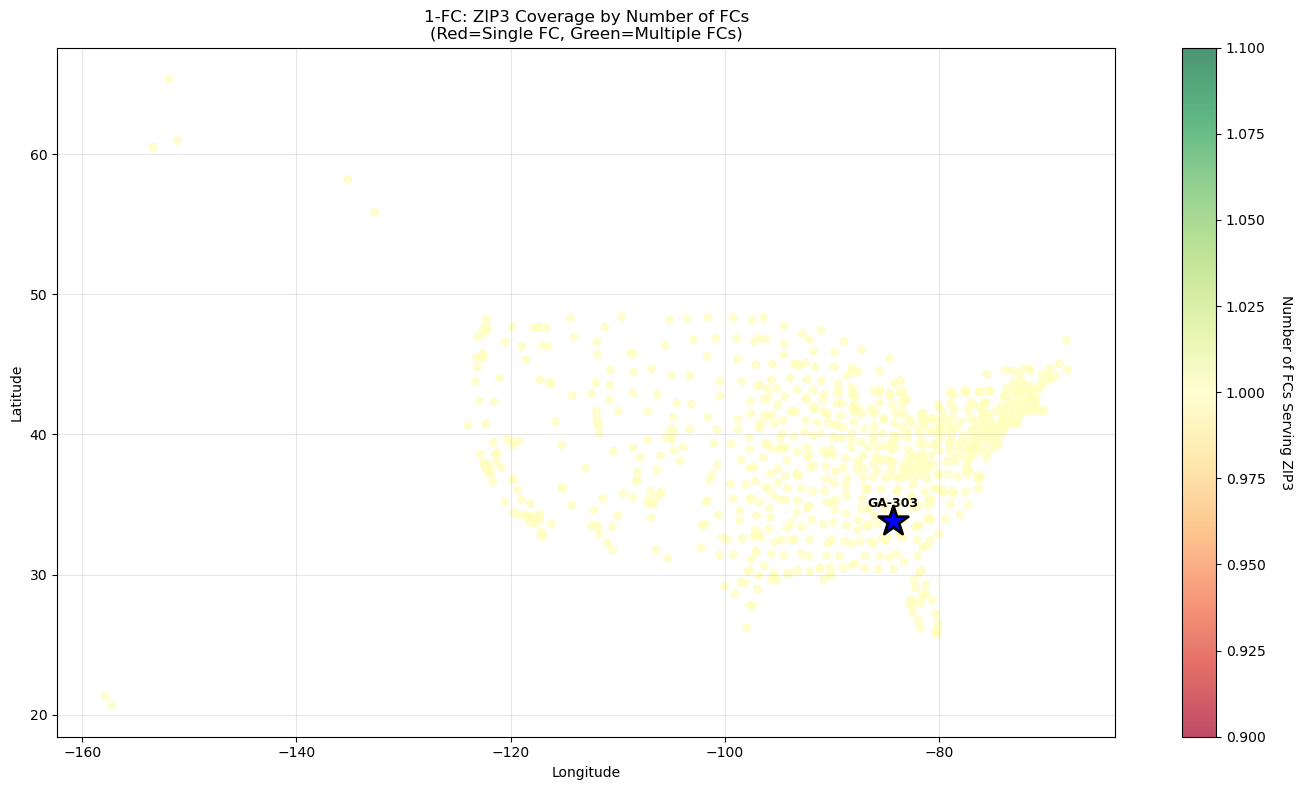

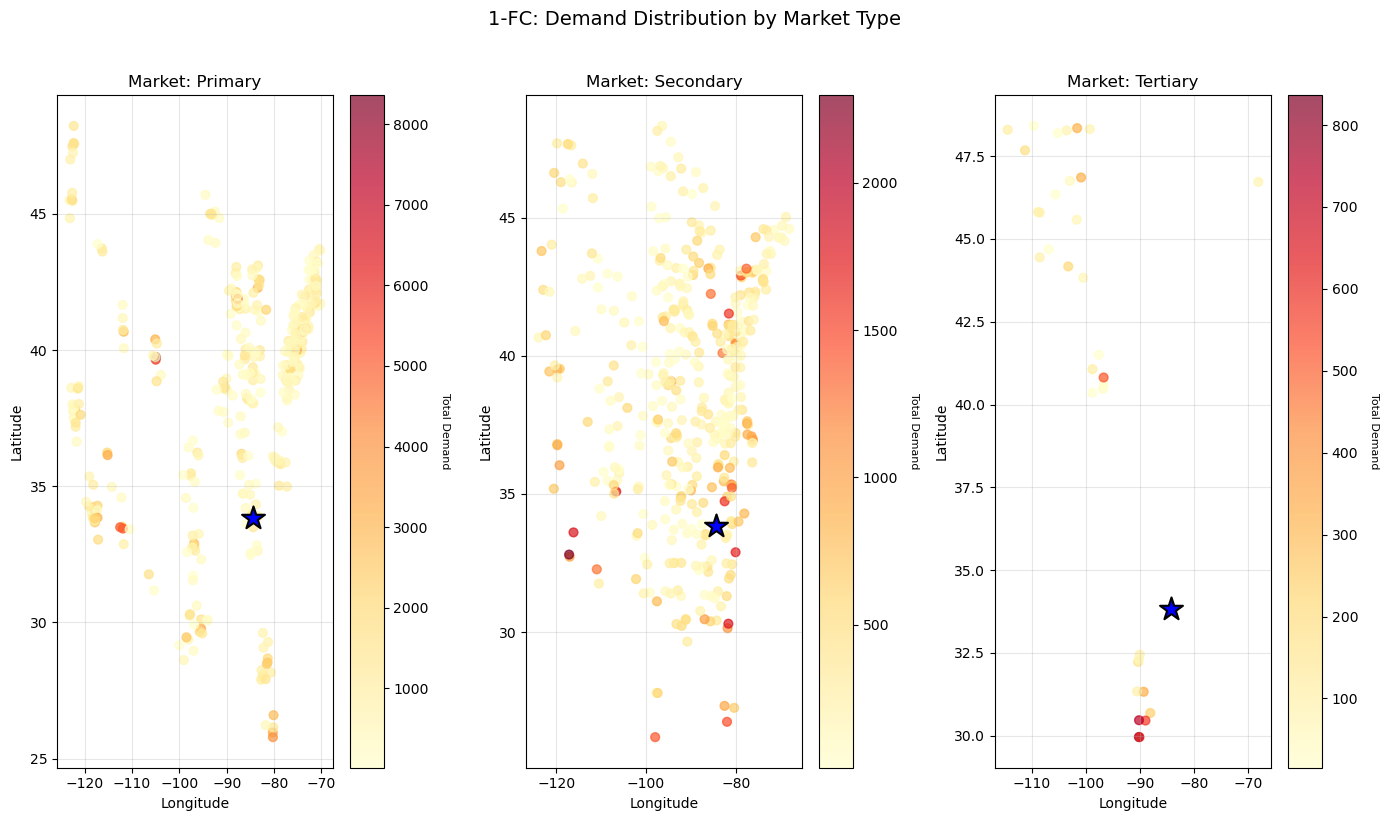


Generating plots for 4-FC...


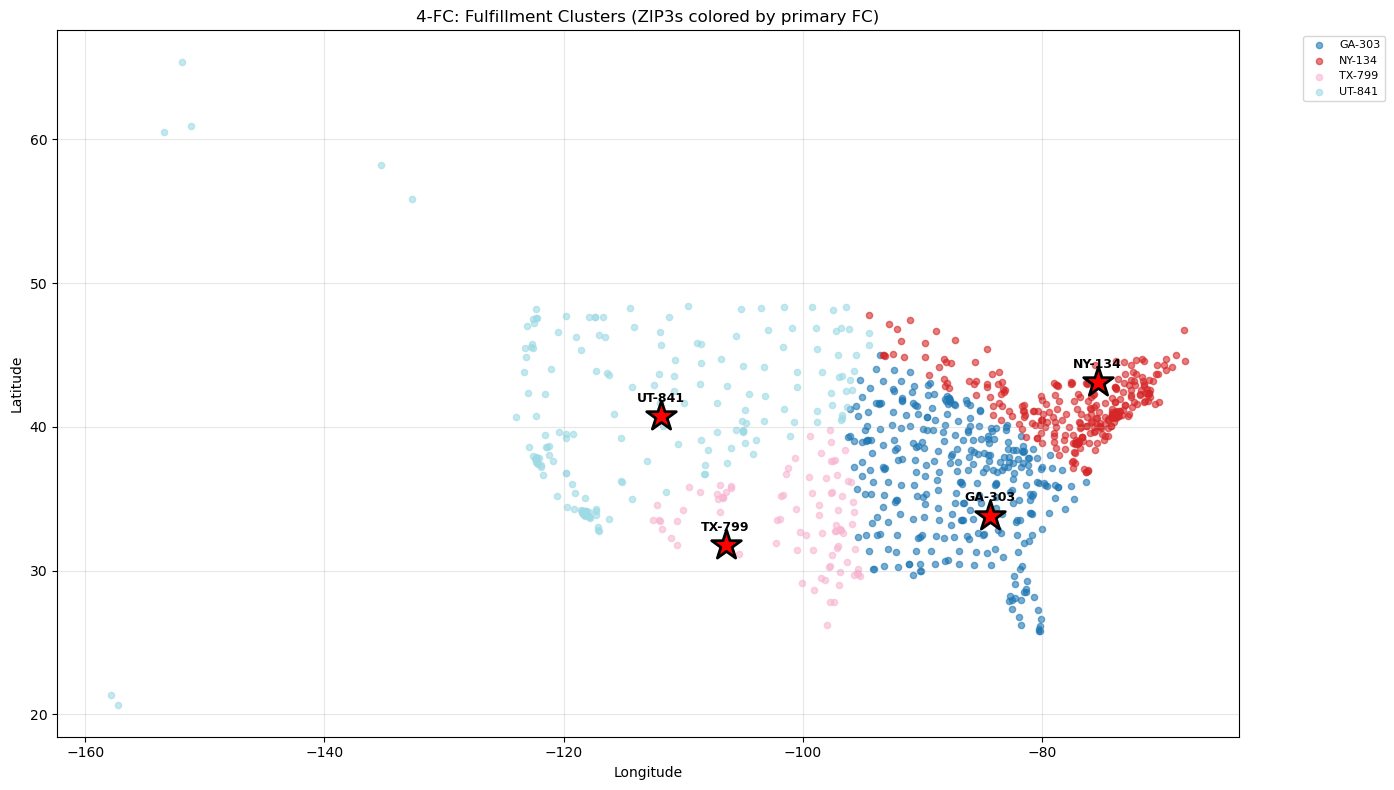

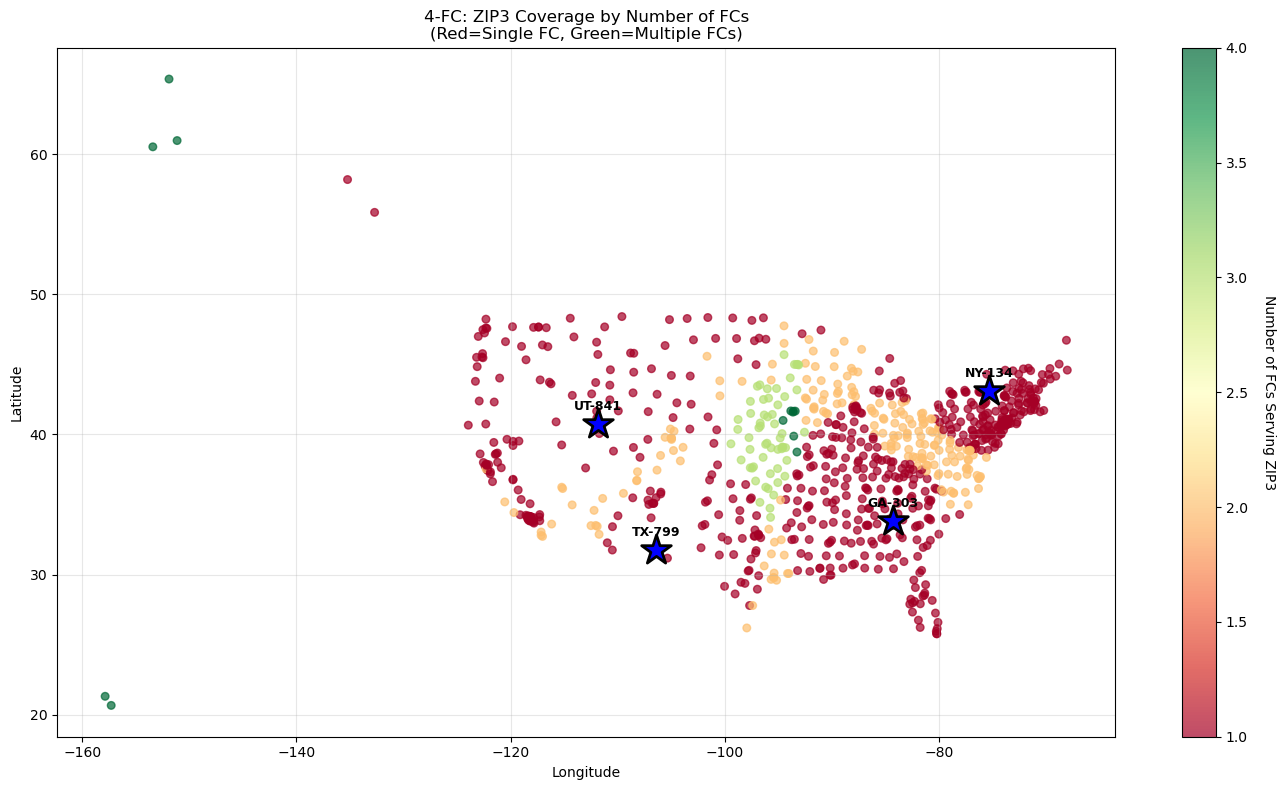

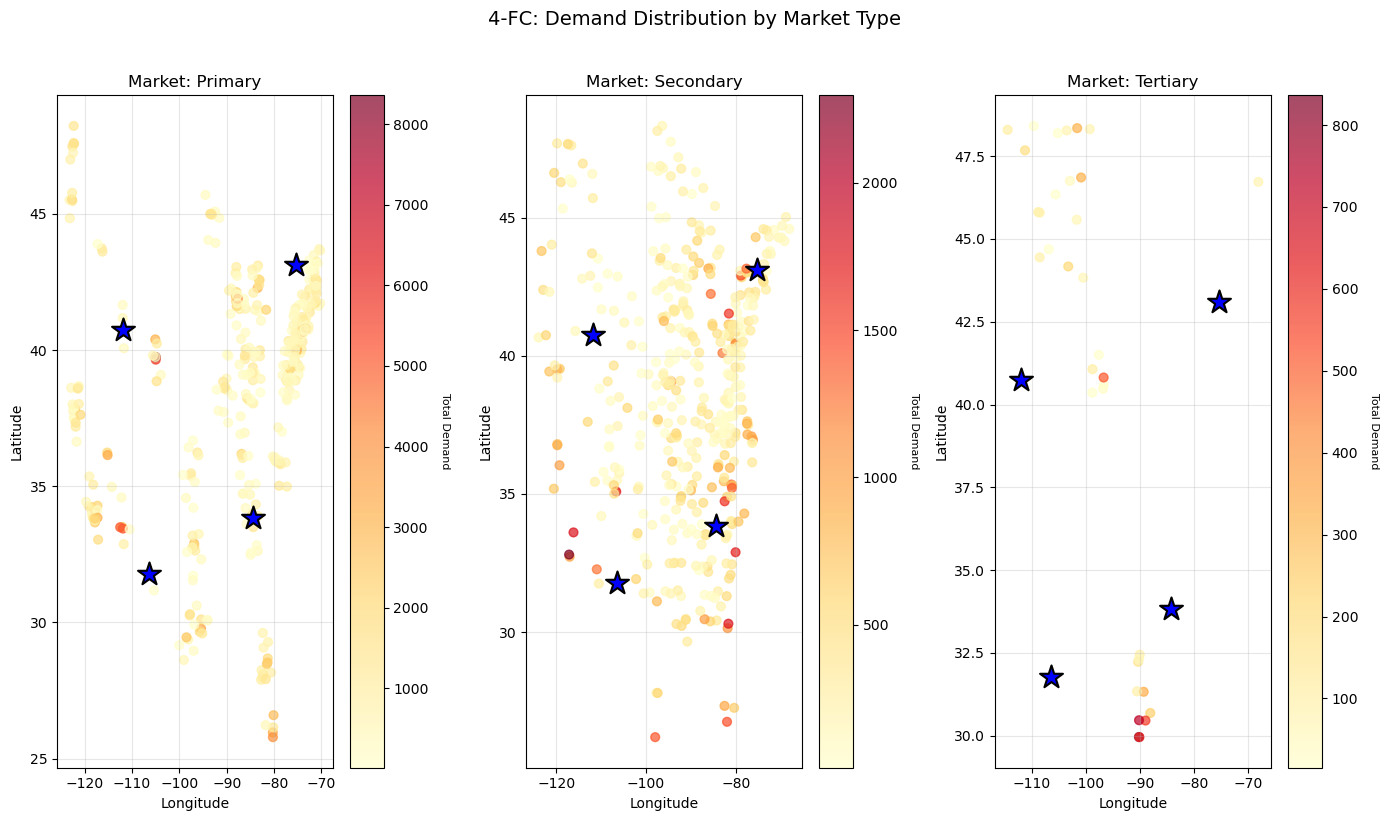


Generating plots for 15-FC...


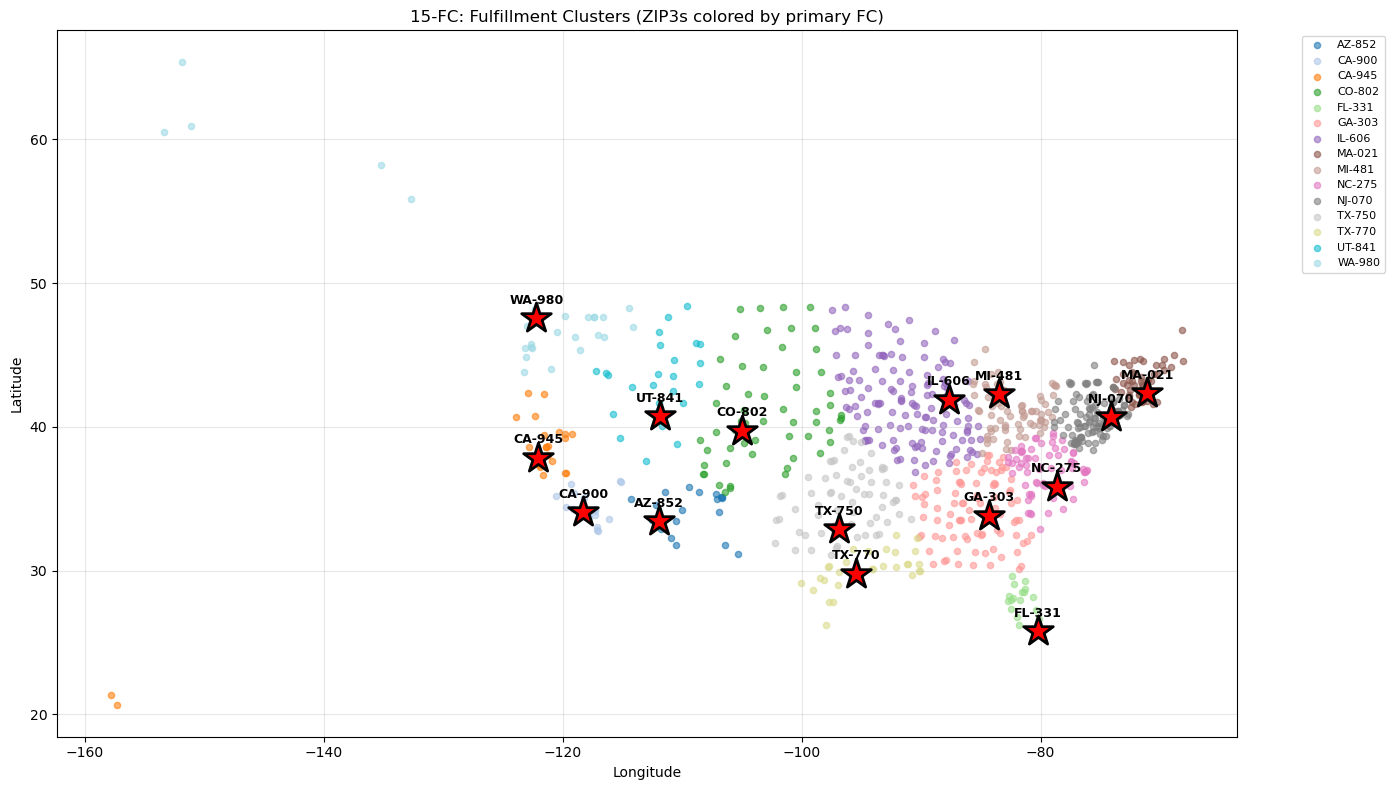

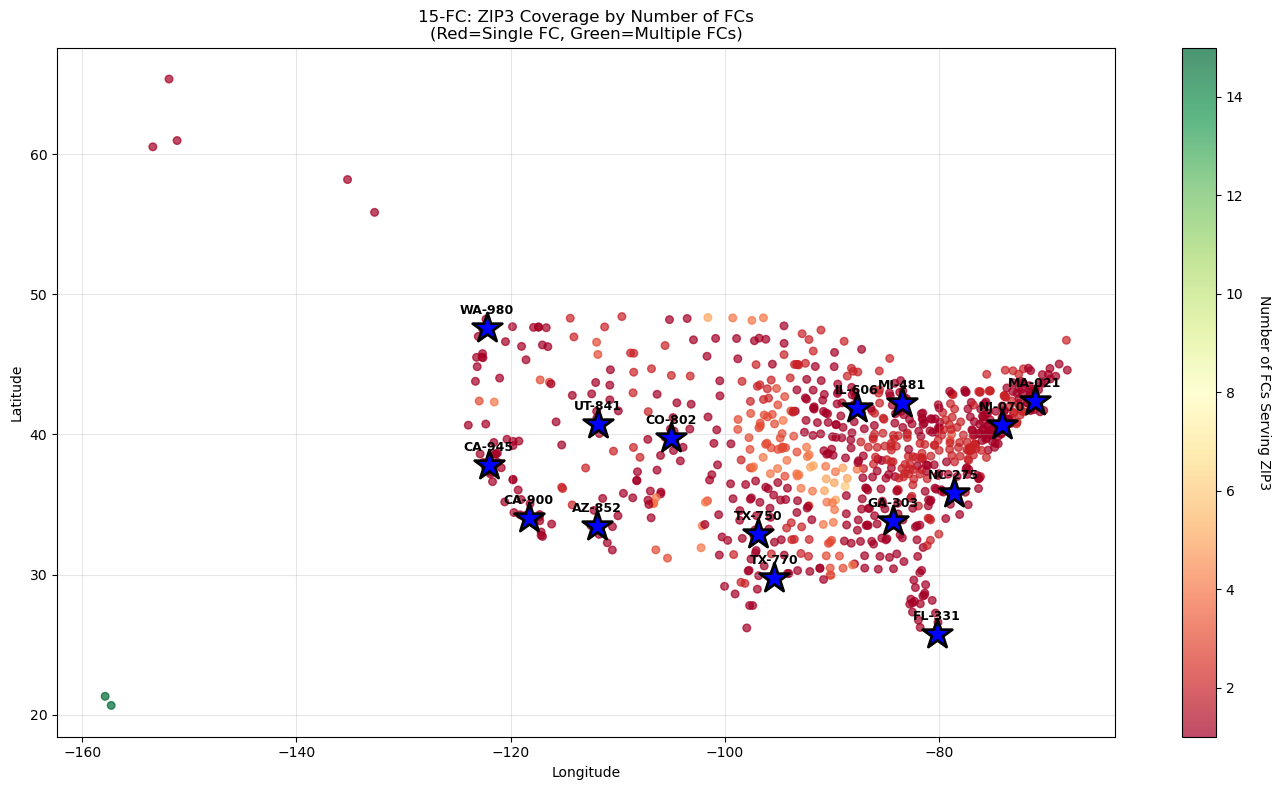

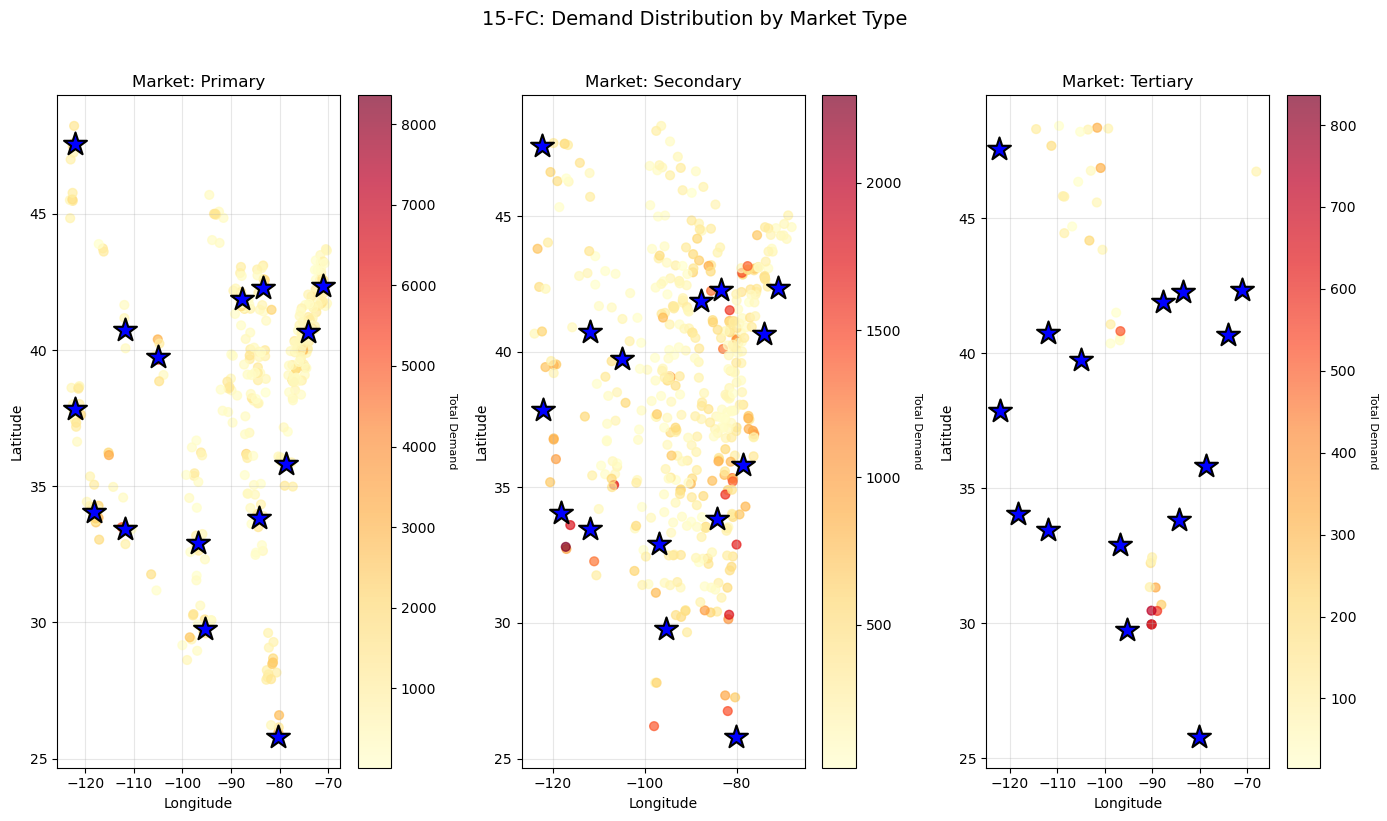

In [7]:
# Generate visualizations for all scenarios
for scenario_name, network in networks.items():
    print(f"\nGenerating plots for {scenario_name}...")
    
    # Task 4a: Fulfillment clusters
    fig1 = plot_fulfillment_clusters(network, scenario_name)
    plt.show()
    
    # Task 4b: Number of FCs serving each cluster
    fig2 = plot_fc_count_clusters(network, scenario_name)
    plt.show()
    
    # Demand by market type geography
    fig3 = plot_demand_by_market_geography(network, scenario_name)
    plt.show()

In [18]:
# use 15Fc scenario as an example   

network_15fc = networks['15-FC']
alloc = network_15fc.zip3_fc_allocation

fc_list = ['GA-303', 'CA-900', 'CA-945', 'UT-841']

for fc in fc_list:
    alloc_fc = alloc[alloc['FC'] == fc]

    demand_ZIP3 = demand_df.loc[
        demand_df['ZIP3'].isin(alloc_fc['ZIP3'].values)][['Day', 'ZIP3', 'Mean_Demand']]

    overall = demand_ZIP3['Mean_Demand'].sum()

    print(f"Demand allocated for Fc {fc}:", overall)

Demand allocated for Fc GA-303: 52886.26999999999
Demand allocated for Fc CA-900: 47128.94
Demand allocated for Fc CA-945: 22846.99
Demand allocated for Fc UT-841: 14486.13


In [ ]:
# save 15fc scenario allocation

alloc.to_csv('data/zip3_fc_allocation_15fc.csv', index=False)